# Phân loại chủ đề tin tức AG News bằng DistilBERT

Thực hiện yêu cầu trong `yeucau.txt`: Transformer cho phân loại văn bản và so sánh
**fine-tuning toàn bộ mô hình** với **đóng băng encoder, chỉ huấn luyện head**.

Nhãn CSV: 1 = World (Thế giới), 2 = Sports (Thể thao), 3 = Business (Kinh doanh),
4 = Sci/Tech (Khoa học/Công nghệ). Đây là dữ liệu tiếng Anh.

Chạy các cell từ trên xuống. Mặc định `QUICK_RUN=True` chỉ để kiểm tra quy trình;
đổi thành `False` để chạy thí nghiệm đầy đủ. Lần đầu cần Internet để tải
`distilbert/distilbert-base-uncased`. Nên dùng GPU; CPU có thể rất chậm.
Notebook chưa chứa kết quả huấn luyện giả lập hay điểm số được điền sẵn.

## 1. Môi trường
Từ terminal tại thư mục dự án: `python -m pip install -r requirements.txt`.
Sau đó chạy `python -m jupyterlab` và mở notebook này.
Nếu cài thư viện trong notebook bằng cell dưới, khởi động lại kernel sau khi cài.

In [1]:
# Bỏ dấu # nếu chưa cài môi trường:
# %pip install -r requirements.txt

In [2]:
from pathlib import Path
from datetime import datetime
import gc
import html
import json
import random
import re
import time
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
QUICK_RUN = True
MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16  # Giảm xuống 8 hoặc 4 nếu thiếu VRAM.
EPOCHS = 1 if QUICK_RUN else 3
LEARNING_RATES = {"frozen_encoder": 1e-3, "fine_tuning": 2e-5}
LABELS = ["World", "Sports", "Business", "Sci/Tech"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
DATA_DIR = ROOT / "datasets"
RUN_DIR = ROOT / "outputs" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_DIR.mkdir(parents=True, exist_ok=False)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print("Device:", DEVICE, "| Quick run:", QUICK_RUN, "| Output:", RUN_DIR)
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)

c:\Users\CA\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu | Quick run: True | Output: c:\Users\CA\Documents\ChatGPT\AG-New\outputs\20261102_215429_292430
PyTorch: 2.14.1+cpu | Transformers: 5.20.2


## 2. Đọc và kiểm tra dữ liệu
Ghép Title và Description, giải mã HTML và chuẩn hóa khoảng trắng. Giữ từ dừng,
dấu câu và cấu trúc câu cho tokenizer của Transformer. Xóa bản ghi trùng văn bản
trong train trước khi chia validation, tránh cùng văn bản xuất hiện ở cả hai tập.
Test giữ nguyên làm tập đánh giá cuối cùng; báo cáo số văn bản giao nhau với train.
Không dùng nhãn test để chọn epoch hoặc mô hình.

,train,test
label,,
World,30000,1900
Sports,30000,1900
Business,30000,1900
Sci/Tech,30000,1900


Kích thước gốc: 120000 7600
Số văn bản trùng trong train: 83
Số văn bản có nhãn mâu thuẫn: 15
Số bản ghi test có văn bản cũng nằm trong train: 4
Train / validation / test dùng trong lần chạy: 2000 400 400


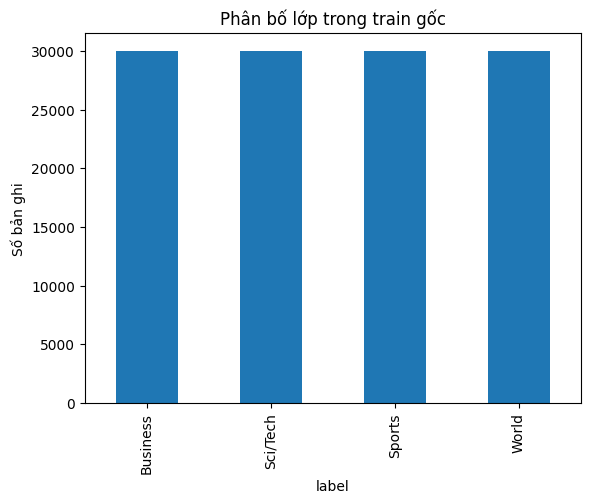

In [3]:
def clean_text(text):
    text = html.unescape(str(text)).replace("\\", " ")
    return re.sub(r"\s+", " ", text).strip()

def read_news(path):
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy {path}. Hãy mở notebook từ thư mục dự án.")
    frame = pd.read_csv(path)
    required = {"Class Index", "Title", "Description"}
    if not required.issubset(frame.columns):
        raise ValueError(f"CSV phải có các cột: {required}")
    if not frame["Class Index"].isin([1, 2, 3, 4]).all():
        raise ValueError("Nhãn không hợp lệ hoặc bị thiếu; cần số nguyên từ 1 đến 4.")
    frame["text"] = (frame["Title"].fillna("") + " " + frame["Description"].fillna("")).map(clean_text)
    if frame["text"].eq("").any():
        raise ValueError("Có bản ghi không có nội dung.")
    frame["label"] = frame["Class Index"].astype(int) - 1
    return frame[["text", "label"]]

raw_train = read_news(DATA_DIR / "train.csv")
test_df = read_news(DATA_DIR / "test.csv")
display(pd.DataFrame({"train": raw_train.label.value_counts().sort_index(),
                      "test": test_df.label.value_counts().sort_index()}).rename(index=dict(enumerate(LABELS))))
print("Kích thước gốc:", len(raw_train), len(test_df))
print("Số văn bản trùng trong train:", raw_train.text.duplicated().sum())
print("Số văn bản có nhãn mâu thuẫn:", (raw_train.groupby("text").label.nunique() > 1).sum())
# Loại toàn bộ văn bản có nhãn mâu thuẫn, rồi giữ một bản của mỗi văn bản.
consistent = raw_train.groupby("text").label.transform("nunique").eq(1)
pool = raw_train.loc[consistent].drop_duplicates("text").reset_index(drop=True)
print("Số bản ghi test có văn bản cũng nằm trong train:", test_df.text.isin(pool.text).sum())
train_df, val_df = train_test_split(pool, test_size=0.1, stratify=pool.label, random_state=SEED)

def stratified_limit(frame, size):
    if size is None or size >= len(frame):
        return frame.reset_index(drop=True)
    subset, _ = train_test_split(frame, train_size=size, stratify=frame.label, random_state=SEED)
    return subset.reset_index(drop=True)

train_df = stratified_limit(train_df, 2000 if QUICK_RUN else None)
val_df = stratified_limit(val_df, 400 if QUICK_RUN else None)
test_df = stratified_limit(test_df, 400 if QUICK_RUN else None)
assert set(train_df.text).isdisjoint(set(val_df.text))
print("Train / validation / test dùng trong lần chạy:", len(train_df), len(val_df), len(test_df))
raw_train.label.map(dict(enumerate(LABELS))).value_counts().plot.bar(title="Phân bố lớp trong train gốc")
plt.ylabel("Số bản ghi")
plt.show()

## 3. Tokenizer và DataLoader
Hai thí nghiệm dùng cùng dữ liệu, seed, tokenizer, batch size và số epoch.
Padding động theo batch; văn bản dài được cắt ở `MAX_LENGTH` token.
Learning rate khác nhau vì head khởi tạo mới cần tốc độ học khác encoder pretrained.
Đây là so sánh hai cấu hình thực hành, chưa phải tìm kiếm siêu tham số tối ưu.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class NewsDataset(Dataset):
    def __init__(self, frame):
        self.encodings = tokenizer(frame.text.tolist(), truncation=True, max_length=MAX_LENGTH)
        self.labels = frame.label.tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        item = {key: value[index] for key, value in self.encodings.items()}
        item["labels"] = self.labels[index]
        return item

train_data, val_data, test_data = [NewsDataset(frame) for frame in (train_df, val_df, test_df)]
collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

def make_loader(dataset, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      collate_fn=collator, num_workers=0, generator=generator)

val_loader = make_loader(val_data)
test_loader = make_loader(test_data)

c:\Users\CA\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\CA\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 4. Huấn luyện và đánh giá
Với frozen encoder, `requires_grad=False` cho backbone và đặt backbone ở `eval()`
để tắt dropout trong encoder; classification head vẫn được học.
Chọn checkpoint có **validation macro-F1 cao nhất** riêng cho mỗi thí nghiệm.
Đo thời gian vòng huấn luyện + validation + lưu checkpoint, không tính tải mô hình
hoặc tokenization. Seed hỗ trợ tái lập, nhưng phần cứng khác có thể cho kết quả khác.

In [5]:
def build_model(mode):
    if mode not in LEARNING_RATES:
        raise ValueError(f"Chế độ không hợp lệ: {mode}")
    seed_everything()
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=4,
        id2label=dict(enumerate(LABELS)), label2id={v: k for k, v in enumerate(LABELS)})
    if mode == "frozen_encoder":
        for parameter in model.base_model.parameters():
            parameter.requires_grad = False
    return model.to(DEVICE)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, targets, predictions = 0.0, [], []
    for batch in loader:
        batch = {key: value.to(DEVICE) for key, value in batch.items()}
        output = model(**batch)
        total_loss += output.loss.item() * len(batch["labels"])
        targets.extend(batch["labels"].cpu().tolist())
        predictions.extend(output.logits.argmax(-1).cpu().tolist())
    return {"loss": total_loss / len(targets),
            "accuracy": accuracy_score(targets, predictions),
            "macro_f1": f1_score(targets, predictions, labels=list(range(4)), average="macro", zero_division=0)}, targets, predictions

def train_experiment(mode):
    model = build_model(mode)
    train_loader = make_loader(train_data, shuffle=True)
    parameters = [p for p in model.parameters() if p.requires_grad]
    trainable = sum(p.numel() for p in parameters)
    total = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.AdamW(parameters, lr=LEARNING_RATES[mode], weight_decay=0.01)
    folder = RUN_DIR / mode
    folder.mkdir(parents=True, exist_ok=True)
    best_f1, best_epoch, history = -1.0, 0, []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        if mode == "frozen_encoder":
            model.base_model.eval()
        loss_sum = 0.0
        for batch in tqdm(train_loader, desc=f"{mode}: epoch {epoch}/{EPOCHS}"):
            batch = {key: value.to(DEVICE) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            output = model(**batch)
            output.loss.backward()
            torch.nn.utils.clip_grad_norm_(parameters, max_norm=1.0)
            optimizer.step()
            loss_sum += output.loss.item() * len(batch["labels"])
        metrics, _, _ = evaluate(model, val_loader)
        row = {"epoch": epoch, "train_loss": loss_sum / len(train_data),
               **{f"val_{key}": value for key, value in metrics.items()}}
        history.append(row)
        print(row)
        if metrics["macro_f1"] > best_f1:
            best_f1, best_epoch = metrics["macro_f1"], epoch
            model.save_pretrained(folder)
            tokenizer.save_pretrained(folder)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    seconds = time.perf_counter() - started
    pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
    del optimizer, parameters, model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return {"mode": mode, "best_epoch": best_epoch, "val_macro_f1": best_f1,
            "trainable_parameters": trainable, "total_parameters": total,
            "training_seconds": seconds, "learning_rate": LEARNING_RATES[mode]}, history

In [6]:
config = {"seed": SEED, "quick_run": QUICK_RUN, "model": MODEL_NAME,
          "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
          "learning_rates": LEARNING_RATES, "labels": LABELS,
          "split_sizes": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
          "device": str(DEVICE), "python": platform.python_version(),
          "torch": torch.__version__, "transformers": transformers.__version__}
(RUN_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
training_results, histories = [], {}
for mode in ("frozen_encoder", "fine_tuning"):
    result, history = train_experiment(mode)
    training_results.append(result)
    histories[mode] = history

# Chọn phương án bằng validation trước khi xem kết quả test.
selected_mode = max(training_results, key=lambda row: row["val_macro_f1"])["mode"]
print("Phương án chọn theo validation:", selected_mode)

c:\Users\CA\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\CA\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1462.38it/s]
[transformers] DistilBertForSequenceClassification LOAD REPO

{'epoch': 1, 'train_loss': 0.5303648200035095, 'val_loss': 0.42410062670707704, 'val_accuracy': 0.8375, 'val_macro_f1': 0.8352468796169583}


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 798.10it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
fine_tuning: epoch 1/1: 100%|██████████| 125/125 [05:21<00:00,  2.57s/it]


{'epoch': 1, 'train_loss': 0.6539644587635994, 'val_loss': 0.3691249594092369, 'val_accuracy': 0.88, 'val_macro_f1': 0.8799316963719173}


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.38s/it]


Phương án chọn theo validation: fine_tuning


## 5. So sánh trên test
Đánh giá checkpoint tốt nhất của cả hai cấu hình, báo cáo Accuracy, macro-F1,
precision/recall/F1 từng lớp và confusion matrix. Không dùng test để chỉnh cấu hình.
Kết quả quick run chỉ là kiểm tra quy trình, không đại diện cho toàn bộ AG News.

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 3136.06it/s]


frozen_encoder


,precision,recall,f1-score,support
World,0.810811,0.90,0.853081,100.00
Sports,0.947368,0.90,0.923077,100.00
Business,0.798077,0.83,0.813725,100.00
Sci/Tech,0.855556,0.77,0.810526,100.00
accuracy,0.850000,0.85,0.850000,0.85
macro avg,0.852953,0.85,0.850102,400.00
weighted avg,0.852953,0.85,0.850102,400.00


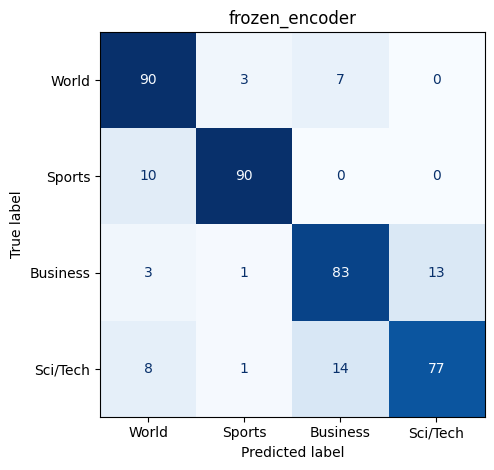

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1254.37it/s]


fine_tuning


,precision,recall,f1-score,support
World,0.965909,0.85,0.904255,100.00
Sports,0.960000,0.96,0.960000,100.00
Business,0.786408,0.81,0.798030,100.00
Sci/Tech,0.788991,0.86,0.822967,100.00
accuracy,0.870000,0.87,0.870000,0.87
macro avg,0.875327,0.87,0.871313,400.00
weighted avg,0.875327,0.87,0.871313,400.00


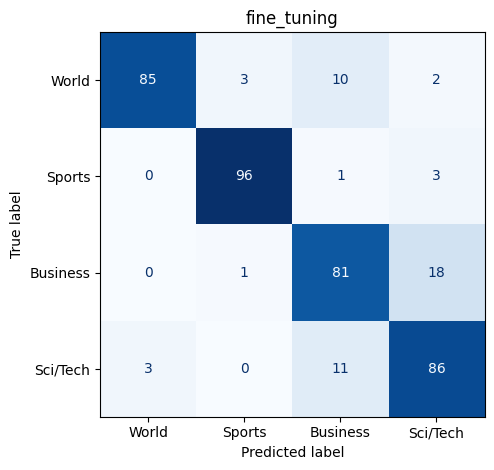

,best_epoch,val_macro_f1,trainable_parameters,total_parameters,training_seconds,learning_rate,test_loss,test_accuracy,test_macro_f1
mode,,,,,,,,,
frozen_encoder,1,0.835247,593668,66956548,118.182677,0.00100,0.415002,0.85,0.850102
fine_tuning,1,0.879932,66956548,66956548,338.719762,0.00002,0.403624,0.87,0.871313


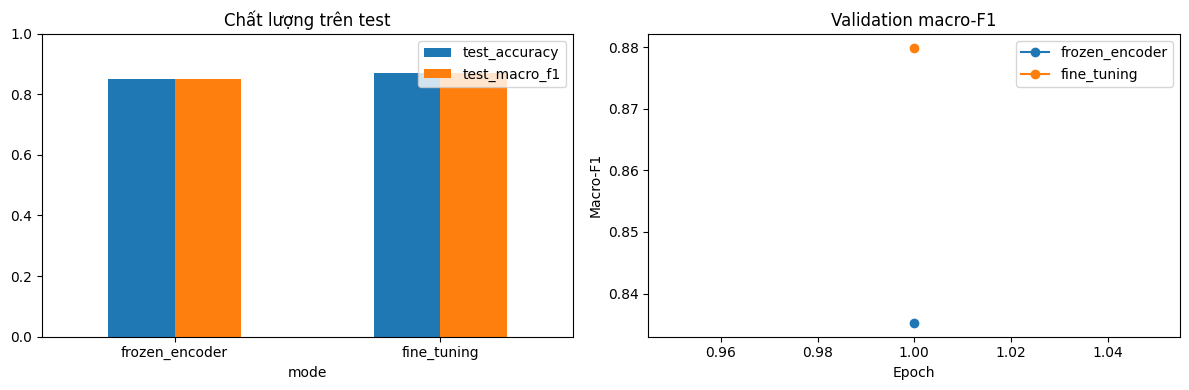

In [7]:
results = []
for training_result in training_results:
    mode = training_result["mode"]
    model = AutoModelForSequenceClassification.from_pretrained(RUN_DIR / mode).to(DEVICE)
    metrics, targets, predictions = evaluate(model, test_loader)
    results.append({**training_result, **{f"test_{k}": v for k, v in metrics.items()}})
    report = classification_report(targets, predictions, labels=list(range(4)),
                                   target_names=LABELS, output_dict=True, zero_division=0)
    pd.DataFrame(report).transpose().to_csv(RUN_DIR / mode / "classification_report.csv")
    pd.DataFrame({"text": test_df.text, "true_label": targets, "predicted_label": predictions}).to_csv(
        RUN_DIR / mode / "test_predictions.csv", index=False)
    print(mode)
    display(pd.DataFrame(report).transpose())
    ConfusionMatrixDisplay.from_predictions(targets, predictions, labels=list(range(4)),
                                            display_labels=LABELS, cmap="Blues", colorbar=False)
    plt.title(mode)
    plt.tight_layout()
    plt.savefig(RUN_DIR / mode / "confusion_matrix.png", dpi=150)
    plt.show()
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

comparison = pd.DataFrame(results).set_index("mode")
comparison.to_csv(RUN_DIR / "comparison.csv")
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison[["test_accuracy", "test_macro_f1"]].plot.bar(ax=axes[0], ylim=(0, 1), rot=0)
axes[0].set_title("Chất lượng trên test")
for mode, history in histories.items():
    frame = pd.DataFrame(history)
    axes[1].plot(frame.epoch, frame.val_macro_f1, marker="o", label=mode)
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[1].legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "comparison.png", dpi=150)
plt.show()

## 6. Nạp lại mô hình và dự đoán tin mới
Dùng phương án đã chọn theo validation. Đầu vào là tin tiếng Anh.
Giá trị softmax là điểm mô hình, chưa phải xác suất được hiệu chỉnh.

In [8]:
inference_tokenizer = AutoTokenizer.from_pretrained(RUN_DIR / selected_mode)
inference_model = AutoModelForSequenceClassification.from_pretrained(RUN_DIR / selected_mode).to(DEVICE)
inference_model.eval()

@torch.no_grad()
def predict_news(texts):
    if isinstance(texts, str):
        texts = [texts]
    if not texts or any(not isinstance(t, str) or not t.strip() for t in texts):
        raise ValueError("Cần ít nhất một văn bản không rỗng.")
    encoded = inference_tokenizer([clean_text(t) for t in texts], padding=True,
                                  truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    probabilities = inference_model(**encoded).logits.softmax(dim=-1)
    scores, indices = probabilities.max(dim=-1)
    return pd.DataFrame({"text": texts, "topic": [LABELS[i] for i in indices.cpu().tolist()],
                         "score": scores.cpu().tolist()})

display(predict_news([
    "The team won the championship after a dramatic final match.",
    "Scientists announced a new processor for artificial intelligence.",
    "Global stock markets rose after strong corporate earnings.",
    "World leaders met to discuss peace negotiations."
]))

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1136.67it/s]


,text,topic,score
0,The team won the championship after a dramatic...,Sports,0.939084
1,Scientists announced a new processor for artif...,Sci/Tech,0.913737
2,Global stock markets rose after strong corpora...,Business,0.884263
3,World leaders met to discuss peace negotiations.,World,0.906859


## 7. Nhận xét và hướng phát triển
Sau khi chạy, dùng `comparison.csv` để trả lời:

1. Fine-tuning thay đổi macro-F1 bao nhiêu so với frozen encoder?
2. Chênh lệch thời gian và số tham số được huấn luyện là bao nhiêu?
3. Cặp chủ đề nào bị nhầm nhiều nhất? Xem thêm `test_predictions.csv`.
4. Validation F1 có giảm trong khi train loss giảm không (dấu hiệu overfitting)?

Không kết luận phương án nào tốt hơn khi chưa chạy. Một seed và số epoch bằng nhau
chưa đủ cho kết luận tổng quát; có thể chạy nhiều seed, chọn learning rate bằng validation,
tăng độ dài token và thử BERT trong nghiên cứu tiếp theo. Các văn bản gần trùng nhau
vẫn có thể tồn tại sau bước loại trùng chính xác.

### Nguồn
- [Dữ liệu được chỉ định trong yêu cầu](https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset)
- [AG News dataset card và nhãn](https://huggingface.co/datasets/fancyzhx/ag_news)
- [DistilBERT — Hugging Face](https://huggingface.co/docs/transformers/model_doc/distilbert)